# Plotting
Plotting the value of $\lambda_2$ as a function of the relavent parameter for the two different systems we are interested in (tent map, attractor).

In [1]:
# imports
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import ticker

plt.rcParams.update({
    'font.family': 'serif',        # Matches typical LaTeX document fonts
    'font.size': 12,               # Base font size
    'axes.labelsize': 14,          # Larger axis labels
    'xtick.labelsize': 12,         # Tick sizes
    'ytick.labelsize': 12,
    'legend.fontsize': 12,
    'axes.grid': True,             # Turn on grid
    'grid.alpha': 0.4,             # Make grid faint so it doesn't distract
    'grid.linestyle': '--',        # Dashed grid lines
    'figure.dpi': 300,             # 300 DPI is standard for publication
    # 'text.usetex': True          # Uncomment if you have a full LaTeX engine installed
})

## Plot tent map $\lambda_2$ against $\alpha$

In [2]:
df = pd.read_csv('../../../results/tent_map/l2_vs_alpha.csv', index_col=0)

In [3]:
l2_abs_v_alpha = np.abs(df['lam_2'].str.strip('()').str.replace(' ', '').astype(complex))
assert isinstance(l2_abs_v_alpha, pd.Series), "l2_abs_v_alpha should be a pandas Series"
alphas = l2_abs_v_alpha.index

/tmp/ipykernel_66014/1390138684.py:47: MatplotlibDeprecationWarning: Since Matplotlib 3.10 indicate_inset_[zoom] returns a single InsetIndicator artist with a rectangle property and a connectors property.  From 3.12 it will no longer be possible to unpack the return value into two elements.
  mark, lines = ax.indicate_inset_zoom(axins, edgecolor="black", alpha=0.5, linewidth=1.2) # type: ignore


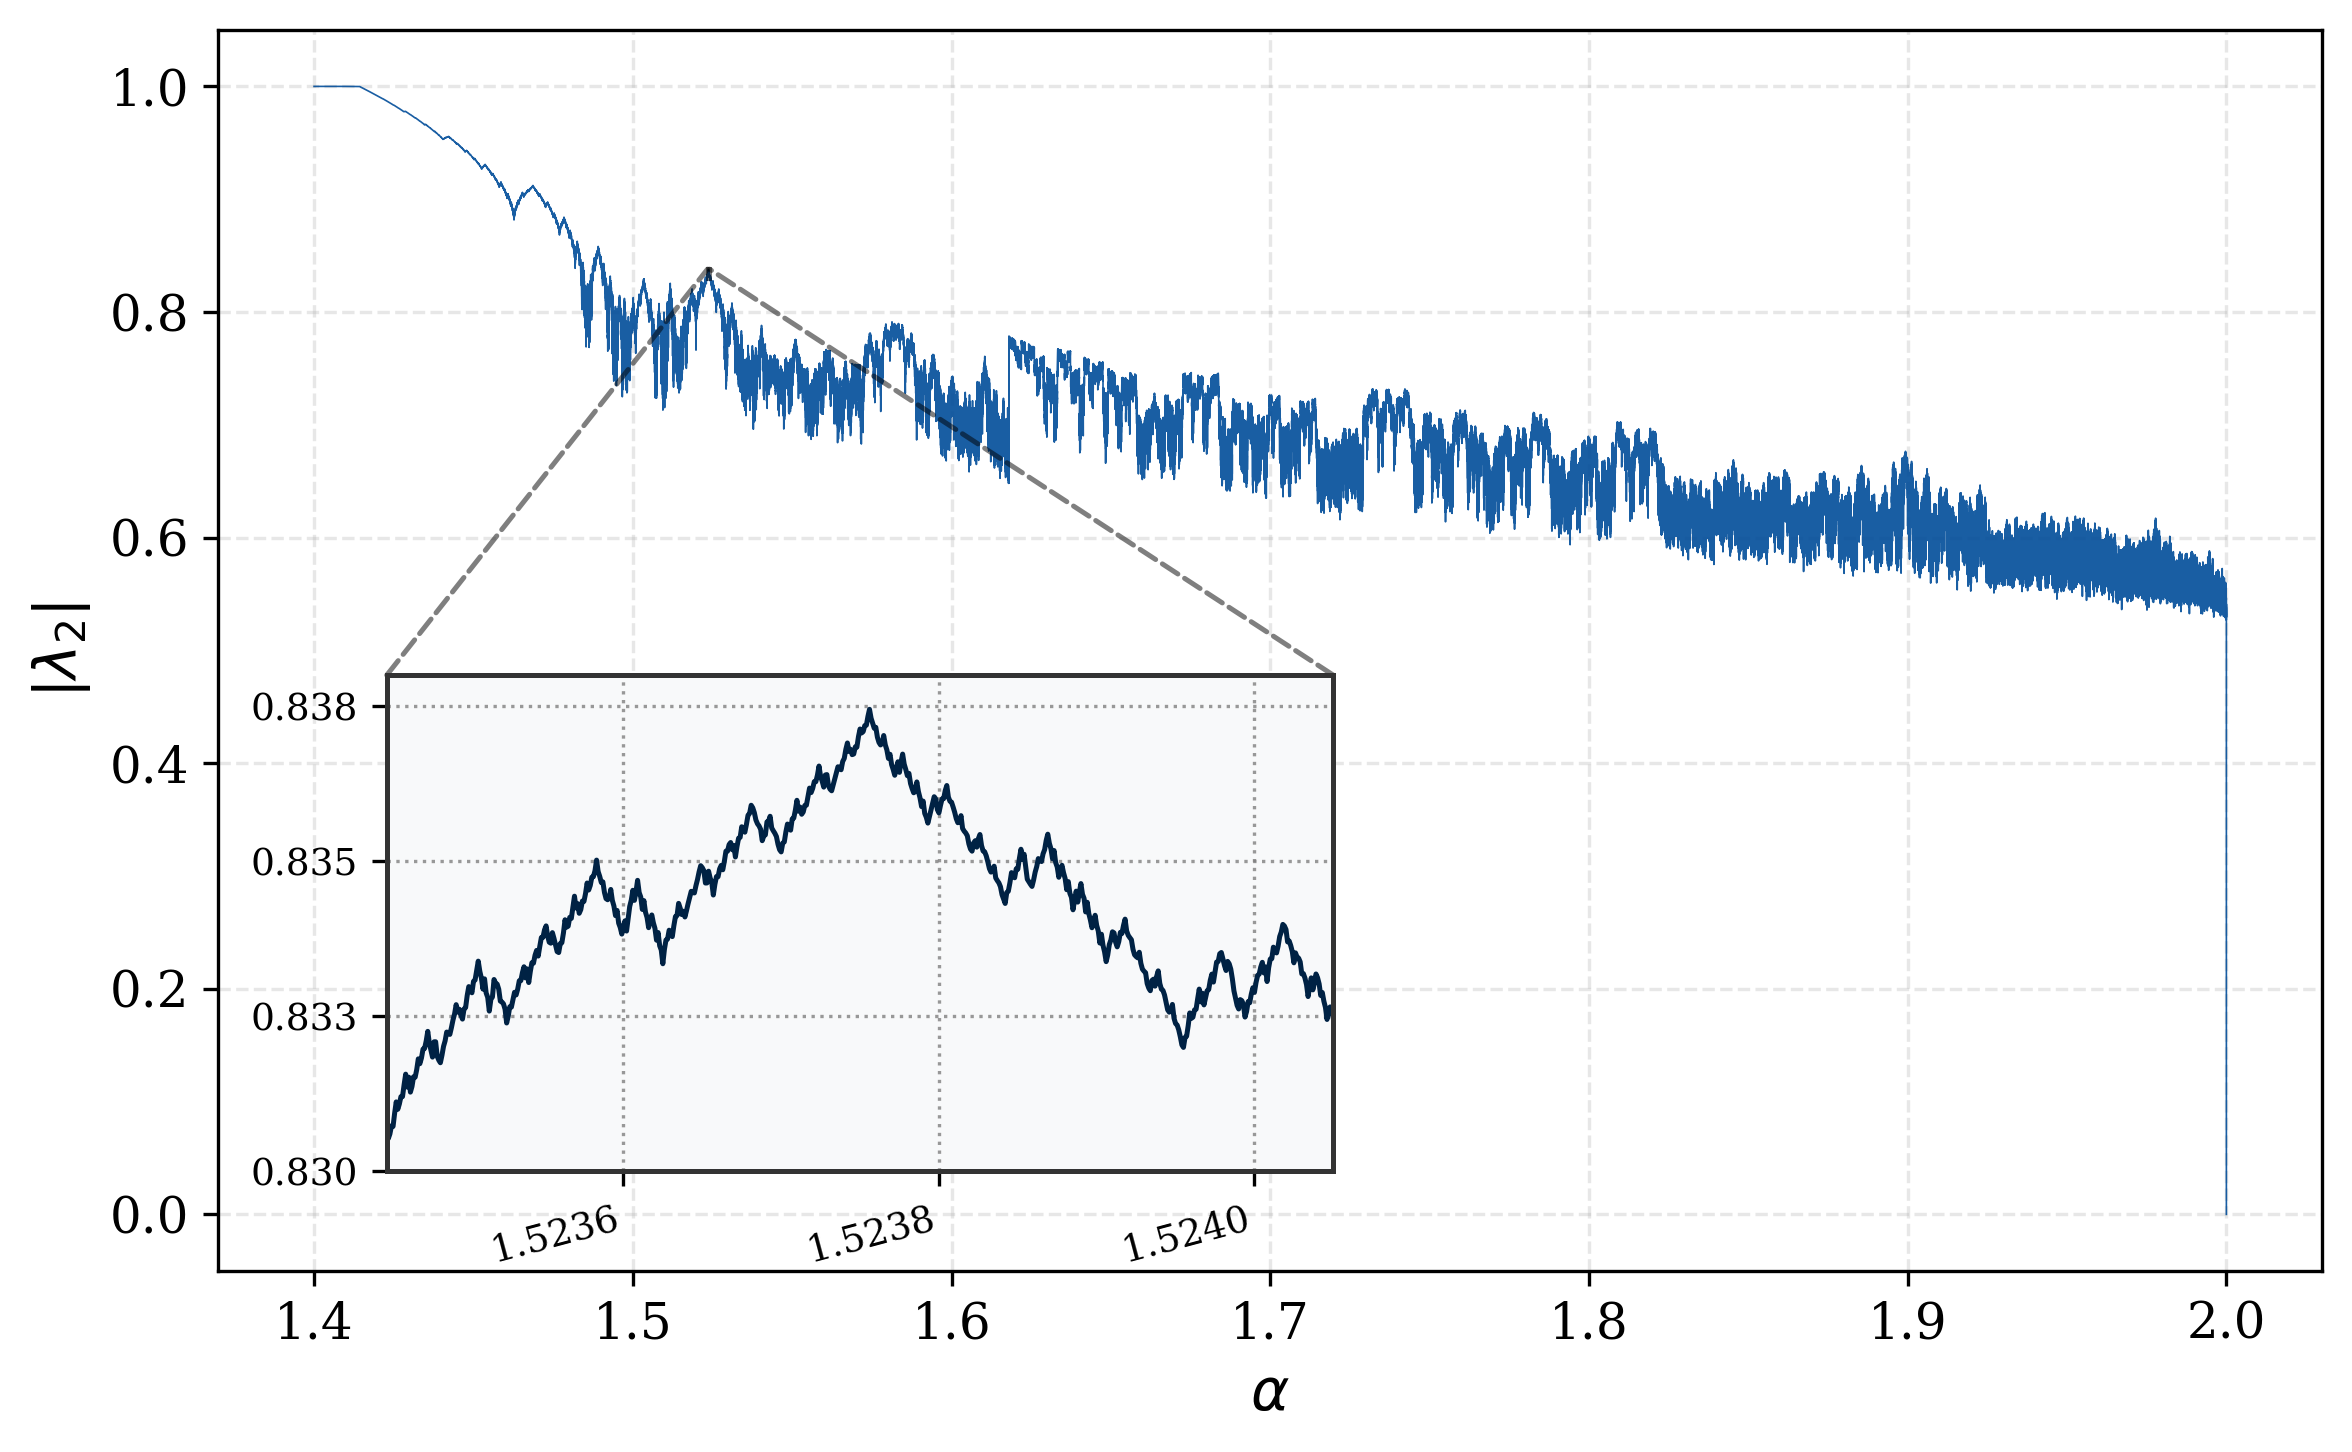

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))

# --- Main Plot ---
ax.plot(alphas, l2_abs_v_alpha, color='#004c99', linewidth=0.4, alpha=0.9)
ax.set_xlabel(r'$\alpha$')
ax.set_ylabel(r'$|\lambda_2|$')

# Main plot grid (subtle)
ax.grid(True, linestyle='--', alpha=0.3)

# --- Inset Plot (The Zoom) ---
axins = ax.inset_axes((0.08, 0.08, 0.45, 0.4))

axins.plot(alphas, l2_abs_v_alpha, color='#002244', linewidth=1.2)

# Your tight Zoom Coordinates
x1, x2 = 1.52375 - 0.0003, 1.52375 + 0.0003
y1, y2 = 0.83, 0.838

axins.set_xlim(x1, x2)
axins.set_ylim(y1, y2)

# --- Prettifying the Inset ---
axins.set_facecolor('#f8f9fa')

# 1. Spacing: Limit the number of ticks
axins.xaxis.set_major_locator(ticker.MaxNLocator(nbins=3))
axins.yaxis.set_major_locator(ticker.MaxNLocator(nbins=4))

# 2. THE FIX: Force strict decimal formatting
# (4 decimals for X to handle the 0.0003 spread, 3 decimals for Y)
axins.xaxis.set_major_formatter(ticker.FormatStrFormatter('%.4f'))
axins.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.3f'))

# 3. THE FIX: Shrink the font slightly and rotate the X-axis labels
# so they don't crash into each other horizontally
plt.setp(axins.get_xticklabels(), rotation=15, ha='right', fontsize=9)
plt.setp(axins.get_yticklabels(), fontsize=9)

# 4. Grid and borders
axins.grid(True, linestyle=':', alpha=0.8, color='gray')
for spine in axins.spines.values():
    spine.set_linewidth(1.2)
    spine.set_color('#333333')

# --- Connect the Main Plot to the Inset ---
mark, lines = ax.indicate_inset_zoom(axins, edgecolor="black", alpha=0.5, linewidth=1.2) # type: ignore
for line in lines:
    line.set_linestyle('--')

plt.tight_layout()
plt.savefig('tent_map_abs_l2_v_alpha.pdf', format='pdf', bbox_inches='tight')
plt.show()

## Plot attractor $\lambda_2$ against $\varepsilon$

In [5]:
l2_attractor = pd.read_csv("../../../results/attractor/res.csv", index_col=0).squeeze()
assert isinstance(l2_attractor, pd.Series)
l2_attractor[l2_attractor == 0] = None

/tmp/ipykernel_66014/444522113.py:39: MatplotlibDeprecationWarning: Since Matplotlib 3.10 indicate_inset_[zoom] returns a single InsetIndicator artist with a rectangle property and a connectors property.  From 3.12 it will no longer be possible to unpack the return value into two elements.
  mark, lines = ax.indicate_inset_zoom(axins, edgecolor="black", alpha=0.5, linewidth=1.2) # type: ignore
/tmp/ipykernel_66014/444522113.py:71: MatplotlibDeprecationWarning: Since Matplotlib 3.10 indicate_inset_[zoom] returns a single InsetIndicator artist with a rectangle property and a connectors property.  From 3.12 it will no longer be possible to unpack the return value into two elements.
  mark, lines = ax.indicate_inset_zoom(axins, edgecolor="black", alpha=0.5, linewidth=1.2) # type: ignore


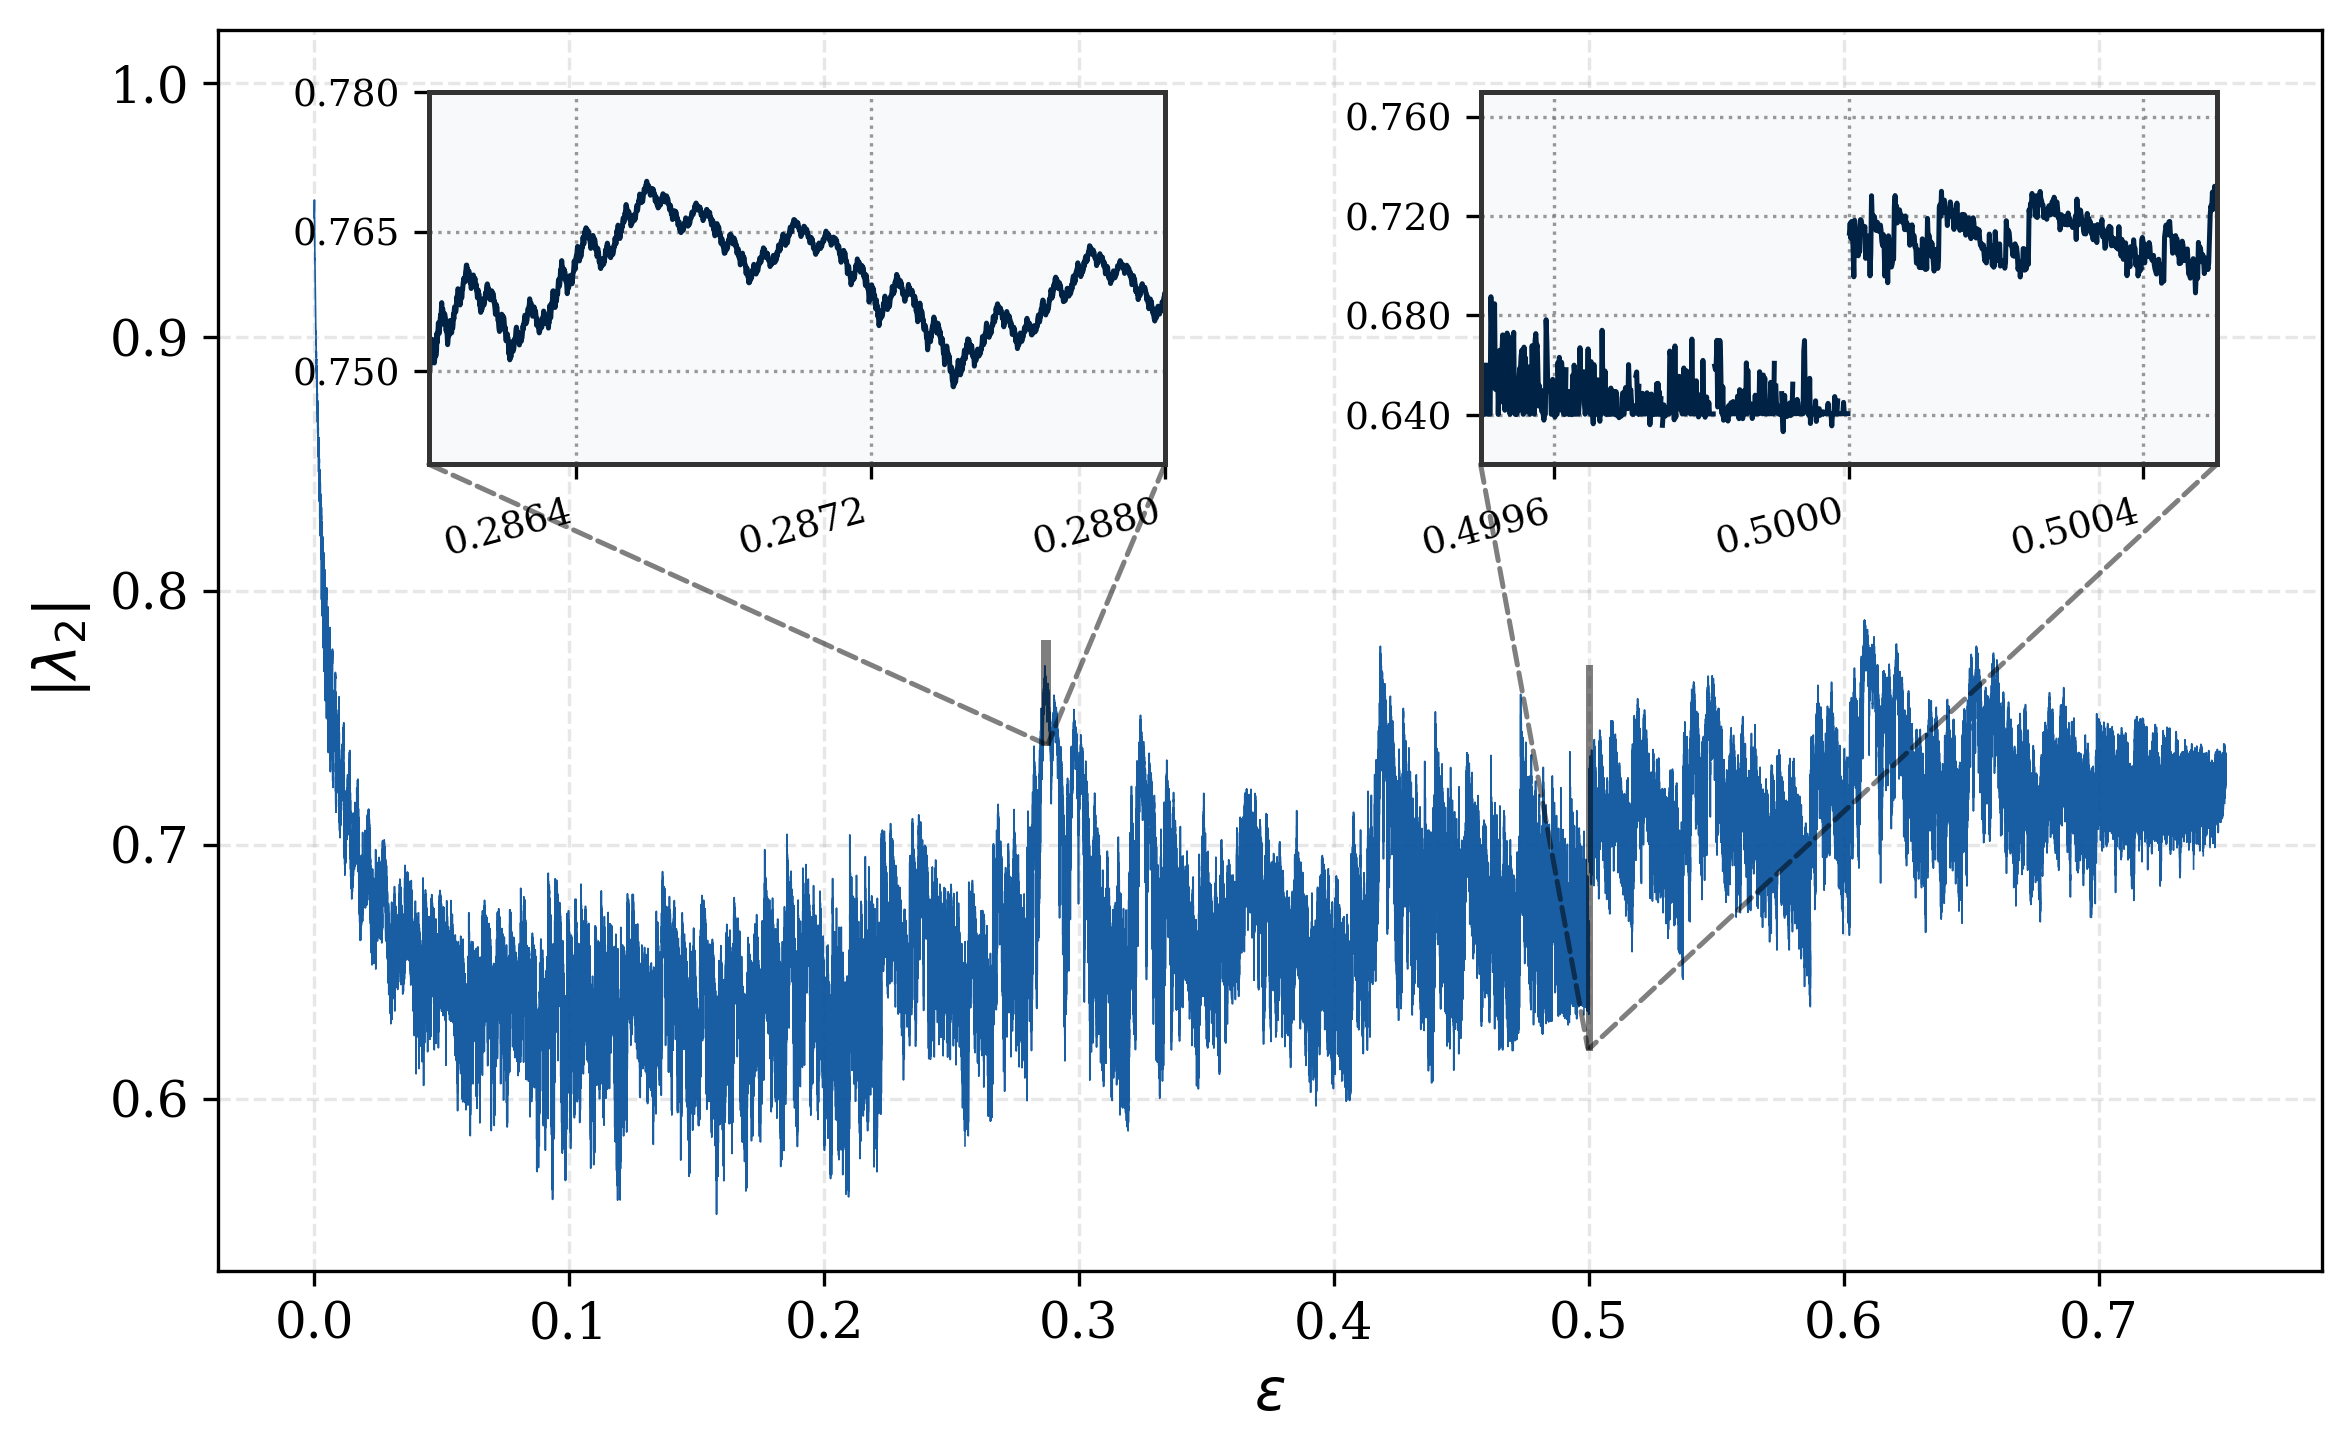

In [6]:
assert isinstance(l2_attractor, pd.Series)

fig, ax = plt.subplots(figsize=(8, 5))

# --- Main Plot ---
ax.plot(l2_attractor.index, l2_attractor, color='#004c99', linewidth=0.4, alpha=0.9)
ax.set_xlabel(r'$\varepsilon$')
ax.set_ylabel(r'$|\lambda_2|$')

ax.grid(True, linestyle='--', alpha=0.3)

# --- Inset 1 ---
axins = ax.inset_axes((0.6, 0.65, 0.35, 0.3))

axins.plot(l2_attractor.index, l2_attractor, color='#002244', linewidth=1.2)

x1, x2 = 0.5-0.0005, 0.5+0.0005
y1, y2 = 0.62, 0.77

axins.set_xlim(x1, x2)
axins.set_ylim(y1, y2)

axins.set_facecolor('#f8f9fa')

axins.xaxis.set_major_locator(ticker.MaxNLocator(nbins=3))
axins.yaxis.set_major_locator(ticker.MaxNLocator(nbins=4))

axins.xaxis.set_major_formatter(ticker.FormatStrFormatter('%.4f'))
axins.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.3f'))

plt.setp(axins.get_xticklabels(), rotation=15, ha='right', fontsize=9)
plt.setp(axins.get_yticklabels(), fontsize=9)

axins.grid(True, linestyle=':', alpha=0.8, color='gray')
for spine in axins.spines.values():
    spine.set_linewidth(1.2)
    spine.set_color('#333333')

mark, lines = ax.indicate_inset_zoom(axins, edgecolor="black", alpha=0.5, linewidth=1.2) # type: ignore
for line in lines:
    line.set_linestyle('--')


# --- Inset 2 ---
axins = ax.inset_axes((0.1, 0.65, 0.35, 0.3))

axins.plot(l2_attractor.index, l2_attractor, color='#002244', linewidth=1.2)

x1, x2 = 0.287 - 0.001, 0.287 + 0.001
y1, y2 = 0.74, 0.78

axins.set_xlim(x1, x2)
axins.set_ylim(y1, y2)

axins.set_facecolor('#f8f9fa')

axins.xaxis.set_major_locator(ticker.MaxNLocator(nbins=3))
axins.yaxis.set_major_locator(ticker.MaxNLocator(nbins=4))

axins.xaxis.set_major_formatter(ticker.FormatStrFormatter('%.4f'))
axins.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.3f'))

plt.setp(axins.get_xticklabels(), rotation=15, ha='right', fontsize=9)
plt.setp(axins.get_yticklabels(), fontsize=9)

axins.grid(True, linestyle=':', alpha=0.8, color='gray')
for spine in axins.spines.values():
    spine.set_linewidth(1.2)
    spine.set_color('#333333')

mark, lines = ax.indicate_inset_zoom(axins, edgecolor="black", alpha=0.5, linewidth=1.2) # type: ignore
for line in lines:
    line.set_linestyle('--')


plt.tight_layout()
plt.savefig('attractor_abs_l2_v_eps.pdf', format='pdf', bbox_inches='tight')
plt.show()